# Experiment 2 — Production Rules and the Match Phase

**Aim.** Represent domain knowledge as IF–THEN production rules, hold facts in a working
memory (WM), and compute the *conflict set* of applicable rules.

**Theory.** A production system has three parts: a **rule base** of IF–THEN productions, a
**working memory** of currently believed facts, and an **inference engine** running the
*recognise–act* cycle — match all rules against WM, select one rule from the resulting
conflict set, act by asserting its conclusion, repeat.

This notebook isolates the **match** phase. A rule is *applicable* when

1. every positive condition of its IF part is present in WM,
2. every negated condition (`NOT fact`) is absent from WM — Exercise 2, and
3. its conclusion is **not** already in WM — **refractoriness**, which stops a rule firing
   over and over on the same data.

The set of applicable rules is the **conflict set**. Choosing one member of it is conflict
resolution, the subject of Experiment 5.

## 1. Encoding a rule

Each production is a record: an identifier, a list of conditions, and a conclusion.
A condition written as `"NOT flies"` is negated. The conditions are split into a positive
set and a negative set once, at construction time, so that the match itself is only a
couple of set operations.

In [1]:
import random
import time
from dataclasses import dataclass, field
from typing import List, Set

NEG = "NOT "                      # prefix marking a negated condition


@dataclass
class Rule:
    """A production:  IF <conditions> THEN <conclusion>."""
    rid: str
    conditions: List[str]
    conclusion: str

    positives: Set[str] = field(init=False, repr=False)
    negatives: Set[str] = field(init=False, repr=False)

    def __post_init__(self):
        self.positives = {c for c in self.conditions if not c.startswith(NEG)}
        self.negatives = {c[len(NEG):] for c in self.conditions if c.startswith(NEG)}

    def is_applicable(self, wm: Set[str]) -> bool:
        if not self.positives <= wm:        # a required condition is missing
            return False
        if self.negatives & wm:             # a NOT condition is violated
            return False
        return self.conclusion not in wm    # refractoriness

    def __str__(self):
        return f"{self.rid}: IF {' AND '.join(self.conditions)} THEN {self.conclusion}"

## 2. The match phase

`conflict_set` simply tests every rule against the whole of working memory and collects the
ones that pass. `show_conflict_set` is a small helper for printing WM and the resulting
conflict set together.

In [2]:
def conflict_set(rules: List[Rule], wm: Set[str]) -> List[Rule]:
    """Every rule applicable in the current working memory."""
    return [r for r in rules if r.is_applicable(wm)]


def show_conflict_set(rules, wm, header=""):
    if header:
        print(header)
    print("  WM = {" + ", ".join(sorted(wm)) + "}")
    cs = conflict_set(rules, wm)
    if cs:
        print("  Conflict set:")
        for r in cs:
            print("   ", r)
    else:
        print("  Conflict set: (empty — no rule matches)")
    print()

## 3. The knowledge base

A small animal-identification rule base. R1–R8 use only positive conditions; R9 and R10
carry negated conditions and are used in Exercise 2.

In [3]:
RULE_BASE = [
    Rule("R1",  ["has_hair"],                                   "mammal"),
    Rule("R2",  ["gives_milk"],                                 "mammal"),
    Rule("R3",  ["has_feathers"],                               "bird"),
    Rule("R4",  ["flies", "lays_eggs"],                         "bird"),
    Rule("R5",  ["mammal", "eats_meat"],                        "carnivore"),
    Rule("R6",  ["mammal", "pointed_teeth", "has_claws"],       "carnivore"),
    Rule("R7",  ["carnivore", "tawny_colour", "dark_spots"],    "cheetah"),
    Rule("R8",  ["carnivore", "tawny_colour", "black_stripes"], "tiger"),
    Rule("R9",  ["bird", "NOT flies", "swims"],                 "penguin"),
    Rule("R10", ["mammal", "NOT eats_meat"],                    "herbivore"),
]

for r in RULE_BASE:
    print(r)

R1: IF has_hair THEN mammal
R2: IF gives_milk THEN mammal
R3: IF has_feathers THEN bird
R4: IF flies AND lays_eggs THEN bird
R5: IF mammal AND eats_meat THEN carnivore
R6: IF mammal AND pointed_teeth AND has_claws THEN carnivore
R7: IF carnivore AND tawny_colour AND dark_spots THEN cheetah
R8: IF carnivore AND tawny_colour AND black_stripes THEN tiger
R9: IF bird AND NOT flies AND swims THEN penguin
R10: IF mammal AND NOT eats_meat THEN herbivore


## 4. A single match against a fixed working memory

With `WM = {has_hair, pointed_teeth, has_claws, tawny_colour, black_stripes}` only **R1**
should be applicable. `mammal` has not been derived yet, so R5, R6 and R10 each still have an
unsatisfied condition, and without `carnivore` neither R7 nor R8 can match. R1 fires on
`has_hair` alone and its conclusion `mammal` is absent from WM, so it passes all three tests.

In [4]:
wm = {"has_hair", "pointed_teeth", "has_claws", "tawny_colour", "black_stripes"}
show_conflict_set(RULE_BASE, wm, "-- initial working memory --")

-- initial working memory --
  WM = {black_stripes, has_claws, has_hair, pointed_teeth, tawny_colour}
  Conflict set:
    R1: IF has_hair THEN mammal



## Exercise 1 — Adding facts one at a time

Facts are asserted one by one and the conflict set is printed after each. Two things to watch:

* the conflict set **grows** as conditions become satisfied — e.g. R6 appears only once all
  three of `has_hair`, `pointed_teeth`, `has_claws` are present (and `mammal` is derived);
* it also **shrinks**: R1 leaves as soon as `mammal` enters WM, and R5/R6 leave once
  `carnivore` is present. That is refractoriness — a rule whose conclusion is already
  believed has nothing left to contribute.

By the last step the conflict set should contain **R8** (concluding `tiger`), plus R10 while
`eats_meat` remains unasserted.

In [5]:
wm = set()
show_conflict_set(RULE_BASE, wm, "-- empty working memory --")

incoming = ["has_hair", "pointed_teeth", "has_claws",
            "mammal", "carnivore", "tawny_colour", "black_stripes"]

for fact in incoming:
    wm.add(fact)
    show_conflict_set(RULE_BASE, wm, f"-- after asserting '{fact}' --")

-- empty working memory --
  WM = {}
  Conflict set: (empty — no rule matches)

-- after asserting 'has_hair' --
  WM = {has_hair}
  Conflict set:
    R1: IF has_hair THEN mammal

-- after asserting 'pointed_teeth' --
  WM = {has_hair, pointed_teeth}
  Conflict set:
    R1: IF has_hair THEN mammal

-- after asserting 'has_claws' --
  WM = {has_claws, has_hair, pointed_teeth}
  Conflict set:
    R1: IF has_hair THEN mammal

-- after asserting 'mammal' --
  WM = {has_claws, has_hair, mammal, pointed_teeth}
  Conflict set:
    R6: IF mammal AND pointed_teeth AND has_claws THEN carnivore
    R10: IF mammal AND NOT eats_meat THEN herbivore

-- after asserting 'carnivore' --
  WM = {carnivore, has_claws, has_hair, mammal, pointed_teeth}
  Conflict set:
    R10: IF mammal AND NOT eats_meat THEN herbivore

-- after asserting 'tawny_colour' --
  WM = {carnivore, has_claws, has_hair, mammal, pointed_teeth, tawny_colour}
  Conflict set:
    R10: IF mammal AND NOT eats_meat THEN herbivore

-- afte

## Exercise 2 — Negated conditions

A condition `NOT f` succeeds when `f` is simply **absent** from WM — the *closed-world
assumption*. Its falsity is never proved.

The consequence is that matching is **non-monotonic**: asserting a new fact can *remove* a
rule from the conflict set. Below, R9 (`penguin`) is applicable while `flies` is unknown and
disappears the moment `flies` is asserted; R10 (`herbivore`) gives way to R5 (`carnivore`)
when `eats_meat` arrives.

In [6]:
wm = {"bird", "swims"}
show_conflict_set(RULE_BASE, wm, "-- a bird that swims, flight unknown --")

wm.add("flies")
show_conflict_set(RULE_BASE, wm, "-- after asserting 'flies': R9 is retracted --")

wm = {"mammal"}
show_conflict_set(RULE_BASE, wm, "-- a mammal, nothing else known --")

wm.add("eats_meat")
show_conflict_set(RULE_BASE, wm, "-- after 'eats_meat': R10 out, R5 in --")

-- a bird that swims, flight unknown --
  WM = {bird, swims}
  Conflict set:
    R9: IF bird AND NOT flies AND swims THEN penguin

-- after asserting 'flies': R9 is retracted --
  WM = {bird, flies, swims}
  Conflict set: (empty — no rule matches)

-- a mammal, nothing else known --
  WM = {mammal}
  Conflict set:
    R10: IF mammal AND NOT eats_meat THEN herbivore

-- after 'eats_meat': R10 out, R5 in --
  WM = {eats_meat, mammal}
  Conflict set:
    R5: IF mammal AND eats_meat THEN carnivore



## Exercise 3 — Scaling the match, and why RETE exists

Rules are auto-generated over a pool of 60 possible facts, three conditions each, and matched
against a fixed 30-fact working memory. `time.perf_counter` times one full match cycle,
averaged over many repeats.

In [7]:
def make_random_rules(n_rules, n_facts, conds_per_rule=3, seed=42):
    rng = random.Random(seed)
    facts = [f"f{i}" for i in range(n_facts)]
    return [Rule(f"G{i}", rng.sample(facts, conds_per_rule), f"c{i}")
            for i in range(n_rules)]


N_FACTS, WM_SIZE, REPEATS = 60, 30, 200
rng = random.Random(7)
big_wm = set(rng.sample([f"f{i}" for i in range(N_FACTS)], WM_SIZE))

sizes, times = [], []
print(f"{'rules':>7} {'matches':>9} {'time/cycle (ms)':>17} {'us per rule':>13}")
print("-" * 50)

for n in (10, 50, 100, 250, 500, 1000, 2000):
    rules = make_random_rules(n, N_FACTS)
    t0 = time.perf_counter()
    for _ in range(REPEATS):
        cs = conflict_set(rules, big_wm)
    t1 = time.perf_counter()
    per_cycle = (t1 - t0) / REPEATS
    sizes.append(n); times.append(per_cycle * 1e3)
    print(f"{n:>7} {len(cs):>9} {per_cycle*1e3:>17.4f} {per_cycle/n*1e6:>13.4f}")

  rules   matches   time/cycle (ms)   us per rule
--------------------------------------------------
     10         3            0.0010        0.0996
     50         7            0.0043        0.0859
    100        14            0.0084        0.0840
    250        37            0.0193        0.0774
    500        55            0.0408        0.0816
   1000       117            0.0952        0.0952
   2000       251            0.2281        0.1141


### Reading the table

The last column — microseconds spent *per rule* — stays roughly constant, so total match
time is **linear in the number of rules**: 1000 rules cost about 100× what 10 rules cost.
Absolute figures depend on the machine, but the shape of the result does not.

The plot below should therefore come out as a near-straight line.

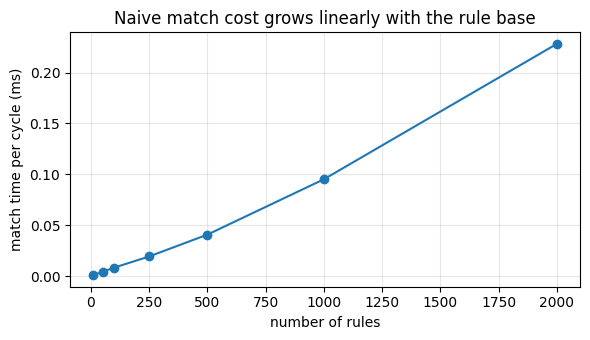

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3.5))
plt.plot(sizes, times, "o-")
plt.xlabel("number of rules")
plt.ylabel("match time per cycle (ms)")
plt.title("Naive match cost grows linearly with the rule base")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Why this motivates RETE

The naive matcher re-tests **every** rule against **all** of working memory on every cycle,
even though the act phase typically changes only one or two facts. Almost all of that work
recomputes results that were already true in the previous cycle.

The **RETE** algorithm removes exactly this redundancy by compiling the rule base into a
dataflow network:

* conditions shared by several rules are tested **once** and the result reused;
* partial matches are stored in **beta memories** and persist across cycles;
* only the facts **added to or removed from** WM are propagated through the network.

Match cost then scales with the *number of changes to WM* rather than with the size of the
rule base, which is what makes rule bases of thousands of productions practical.

## Observations and conclusion

* The conflict set is recomputed from scratch on every cycle and changes as WM changes.
* A rule joins the conflict set only when **all** its conditions are satisfied; a single
  missing condition is enough to exclude it.
* Refractoriness removes a rule once its conclusion is already believed, preventing an
  infinite loop on unchanged data.
* Negated conditions make matching non-monotonic: adding a fact can shrink the conflict set.
* Naive matching is O(number of rules) per cycle, which is why incremental matchers such as
  RETE are used in real production systems.
